# Ames Housing Price Prediction

## Introduction

For this project, our goal was to build a model that predicts house sale prices using the Ames Housing dataset.

During the project, we experimented with different regression models and compared their performance on Kaggle. Support Vector Regression (SVR) was one of the approaches that gave us our strongest results, so we decided to focus on it for our final notebook.

In this notebook, we explain how we prepared the data, created additional features, trained our SVR model, and generated predictions for Kaggle.

## Our approach

1. Load and explore the training and test datasets.
2. Prepare the data and handle missing values.
3. Create additional features based on house characteristics.
4. Build and train an SVR model.
5. Evaluate the model using a validation set.
6. Train the final model on the full training dataset.
7. Generate predictions and prepare our Kaggle submission.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Loading the data

We start by loading the training and test datasets.

The training data contains the house information and actual sale prices, which we use to train our model. The test data contains the house information without the sale prices. Our goal is to predict those missing prices.

In [16]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Set the file paths
train_dataset = '/content/drive/MyDrive/DataBootcamp/Project2/train.csv'
test_dataset = '/content/drive/MyDrive/DataBootcamp/Project2/test.csv'

# Read the datasets
train = pd.read_csv(train_dataset)
test = pd.read_csv(test_dataset)

print("Training dataset shape:", train.shape)
print("Test dataset shape:", test.shape)

# Display the first few rows
train.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training dataset shape: (1200, 81)
Test dataset shape: (260, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Exploring the data

Before building the model, we first look at the datasets to understand what information is available.

We check the column types, summary statistics, and missing values. We also look at the distribution of sale prices to get a better idea of the target variable we are trying to predict.

In [17]:
# Check the data types and non-null values
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1200 non-null   int64  
 1   MSSubClass     1200 non-null   int64  
 2   MSZoning       1200 non-null   object 
 3   LotFrontage    990 non-null    float64
 4   LotArea        1200 non-null   int64  
 5   Street         1200 non-null   object 
 6   Alley          75 non-null     object 
 7   LotShape       1200 non-null   object 
 8   LandContour    1200 non-null   object 
 9   Utilities      1200 non-null   object 
 10  LotConfig      1200 non-null   object 
 11  LandSlope      1200 non-null   object 
 12  Neighborhood   1200 non-null   object 
 13  Condition1     1200 non-null   object 
 14  Condition2     1200 non-null   object 
 15  BldgType       1200 non-null   object 
 16  HouseStyle     1200 non-null   object 
 17  OverallQual    1200 non-null   int64  
 18  OverallC

In [18]:
# Look at the numerical summary statistics
train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1200.000000,1200.000000,990.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1194.000000,1200.000000,...,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,600.500000,57.075000,70.086869,10559.411667,6.105000,5.568333,1971.350833,1984.987500,103.962312,444.886667,...,95.136667,46.016667,22.178333,3.653333,14.980833,1.909167,40.453333,6.311667,2007.810833,181414.628333
std,346.554469,42.682012,23.702029,10619.135549,1.383439,1.120138,30.048408,20.527221,183.534953,439.987844,...,124.034129,65.677629,61.507323,29.991099,54.768057,33.148327,482.323444,2.673104,1.319027,81070.908544
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1875.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,300.750000,20.000000,59.000000,7560.000000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129900.000000
50%,600.500000,50.000000,70.000000,9434.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,385.500000,...,0.000000,24.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163700.000000
75%,900.250000,70.000000,80.000000,11616.000000,7.000000,6.000000,2000.000000,2004.000000,166.750000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1200.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,2260.000000,...,857.000000,523.000000,552.000000,508.000000,410.000000,648.000000,15500.000000,12.000000,2010.000000,755000.000000


In [19]:
# Check the number of missing values in each column
missing_values = train.isnull().sum()

# Only display columns that have missing values
missing_values = missing_values[missing_values > 0]

missing_values.sort_values(ascending=False).head(15)

,0
PoolQC,1196
MiscFeature,1153
Alley,1125
Fence,973
MasVnrType,717
FireplaceQu,564
LotFrontage,210
GarageType,67
GarageFinish,67
GarageQual,67


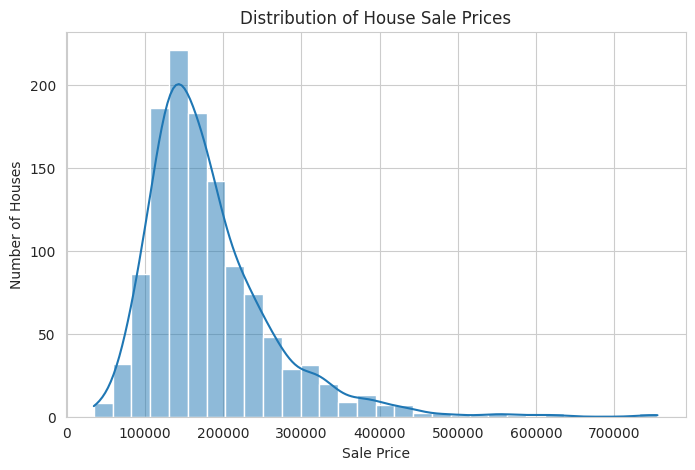

In [20]:
# Look at the distribution of house sale prices

plt.figure(figsize=(8, 5))
sns.histplot(train["SalePrice"], bins=30, kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")

plt.show()

The distribution shows that most houses have lower sale prices, while a smaller number of houses are much more expensive.

To account for this, we use a Yeo-Johnson transformation on the sale price during model training. This helps make the target values more balanced. The model converts its predictions back into regular dollar values afterwards.

In [21]:
# Separate the input features from the target variable
X = train.drop(columns=["Id", "SalePrice"])
y = train["SalePrice"]

# Keep the test features separate
X_test = test.drop(columns=["Id"])

# FIX: Fill missing categorical values with "None" before splitting/feature engineering.
# In the Ames dataset, NA in text columns means "No Feature" (e.g., No Garage, No Basement).
cat_cols = X.select_dtypes(include=['object', 'category']).columns
X[cat_cols] = X[cat_cols].fillna("None")
X_test[cat_cols] = X_test[cat_cols].fillna("None")

# Split the training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

Training features: (960, 79)
Validation features: (240, 79)
Test features: (260, 79)


## 3. Feature engineering

We decided to create some additional features because we thought that combining certain house characteristics could help the model make better predictions.

For example, we created features for total living area, number of bathrooms, house age, garage capacity, and outdoor space. We also combined overall house quality with features such as living area and garage size.

These features give the model some additional information about each property.

## 4. Data preprocessing

Our dataset contains both numerical and categorical variables, as well as missing values, so we needed to prepare these before training the model.

We used the following steps:

- **Numerical columns:** We fill missing values using the median and standardize the values.
- **Categorical columns:** We fill missing values using the most frequent category and use one-hot encoding to convert them into numerical values.

We also use a preprocessing pipeline so that the same steps are applied when training and evaluating the model.

In [22]:
# 1. Define feature engineering functions
def transform_houses(df):
    d = df.copy()

    # Log-transform property sizes
    size_cols = [
        "LotArea", "GrLivArea", "TotalBsmtSF", "1stFlrSF",
        "BsmtFinSF1", "GarageArea", "WoodDeckSF", "OpenPorchSF"
    ]

    for c in size_cols:
        d[f"log_{c}"] = np.log1p(
            pd.to_numeric(d[c], errors="coerce").clip(lower=0)
        )

    # Non-linear property characteristics
    for c in [
        "GrLivArea", "TotalBsmtSF", "LotArea",
        "OverallQual", "YearBuilt", "GarageArea"
    ]:
        d[f"square_{c}"] = pd.to_numeric(
            d[c], errors="coerce"
        ) ** 2

    # Quality interactions
    d["Quality_Living"] = d["OverallQual"] * d["GrLivArea"]
    d["Quality_Basement"] = d["OverallQual"] * d["TotalBsmtSF"]
    d["Quality_Garage"] = d["OverallQual"] * d["GarageArea"]

    # Renovation and property size
    d["Age_Remod"] = d["YearRemodAdd"] - d["YearBuilt"]
    d["Total_Living_Area"] = d["GrLivArea"] + d["TotalBsmtSF"]

    return d


def add_house_features(df):
    df = transform_houses(df.copy())

    def col(name):
        if name in df.columns:
            return pd.to_numeric(
                df[name], errors="coerce"
            ).fillna(0)

        return pd.Series(0.0, index=df.index)

    # Overall property characteristics
    df["Total_Usable_SF"] = (
        col("GrLivArea") + col("TotalBsmtSF")
    )

    df["Total_Bathrooms"] = (
        col("FullBath")
        + 0.5 * col("HalfBath")
        + col("BsmtFullBath")
        + 0.5 * col("BsmtHalfBath")
    )

    df["Total_Rooms"] = col("TotRmsAbvGrd")

    df["Bedroom_Ratio"] = (
        col("BedroomAbvGr") / (col("TotRmsAbvGrd") + 1)
    )

    # Property age (FIXED: missing garage year defaults to YearBuilt)
    df["House_Age"] = (
        col("YrSold") - col("YearBuilt")
    ).clip(lower=0)

    df["Remodel_Age"] = (
        col("YrSold") - col("YearRemodAdd")
    ).clip(lower=0)

    garage_built = pd.to_numeric(df.get("GarageYrBlt"), errors="coerce").fillna(df["YearBuilt"])
    df["Garage_Age"] = (
        col("YrSold") - garage_built
    ).clip(lower=0)

    # Garage and outdoor space
    df["Garage_Capacity"] = col("GarageCars")

    df["Total_Porch_Area"] = (
        col("WoodDeckSF")
        + col("OpenPorchSF")
        + col("EnclosedPorch")
        + col("3SsnPorch")
        + col("ScreenPorch")
    )

    # Quality interactions
    df["Quality_Total_SF"] = (
        col("OverallQual") * df["Total_Usable_SF"]
    )

    df["Quality_Garage_Capacity"] = (
        col("OverallQual") * df["Garage_Capacity"]
    )

    df["Quality_Bathrooms"] = (
        col("OverallQual") * df["Total_Bathrooms"]
    )

    df["Building_Lot_Ratio"] = (
        df["Total_Usable_SF"] / (col("LotArea") + 1)
    )

    return df

In [23]:
# 2. Apply feature engineering to create X_train_eng, X_val_eng, and X_test_eng
X_train_eng = add_house_features(X_train)
X_val_eng = add_house_features(X_val)
X_test_eng = add_house_features(X_test)

print("Feature engineering completed!")
print("Training features:", X_train_eng.shape)
print("Validation features:", X_val_eng.shape)
print("Test features:", X_test_eng.shape)

Feature engineering completed!
Training features: (960, 111)
Validation features: (240, 111)
Test features: (260, 111)


In [24]:
# 3. Identify numerical and categorical features
numeric_features = X_train_eng.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train_eng.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 68
Categorical features: 43


In [25]:
# 4. Preprocessing pipeline setup
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", encoder)
    ]), categorical_features)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


We use an 80/20 split to evaluate the model. The larger portion is used for training, while the remaining 20% is kept aside for validation.

We use a fixed random state so that the split is reproducible. This also allows us to compare experiments using the same validation observations.

## 5. Support Vector Regression (SVR)

For our final model, we use Support Vector Regression with an RBF kernel.

We chose SVR because it can capture relationships between house features and sale prices that are not necessarily linear.

We also apply a Yeo-Johnson transformation to the target variable, which helps us deal with the distribution of sale prices.

We use three main SVR settings:

- **C = 5:** Controls how much the model focuses on fitting the training data.
- **Gamma = 0.008:** Controls how much influence each training observation has.
- **Epsilon = 0.1:** Sets the margin of error the model allows.

In [26]:
svr_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", preprocessor),
        ("svr", SVR(
            kernel="rbf",
            C=5,
            gamma=0.008,
            epsilon=0.1
        ))
    ]),
    transformer=PowerTransformer(method="yeo-johnson")
)

print("Training the selected SVR model...")

svr_model.fit(X_train_eng, y_train)

print("Model training completed!")


Training the selected SVR model...
Model training completed!


## 6. Model evaluation

After training the model, we test it on the validation data that we set aside earlier.

We use Root Mean Squared Error (RMSE) to measure how far the predicted prices are from the actual prices. A lower RMSE means that the predictions are closer to the actual sale prices.

In [27]:
best_svr_model = svr_model

# Predict using engineered validation features
val_predictions = best_svr_model.predict(X_val_eng)

val_predictions = np.maximum(val_predictions, 0)

val_rmse = np.sqrt(
    mean_squared_error(y_val, val_predictions)
)

print(f"Validation RMSE: ${val_rmse:,.2f}")


Validation RMSE: $23,844.42


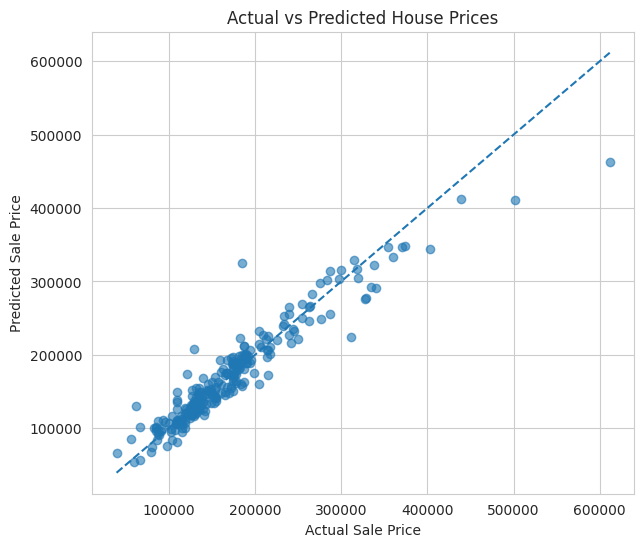

In [28]:
# Compare actual and predicted prices

plt.figure(figsize=(7, 6))

plt.scatter(
    y_val,
    val_predictions,
    alpha=0.6
)

# Add a reference line for perfect predictions
minimum = min(y_val.min(), val_predictions.min())
maximum = max(y_val.max(), val_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")

plt.show()

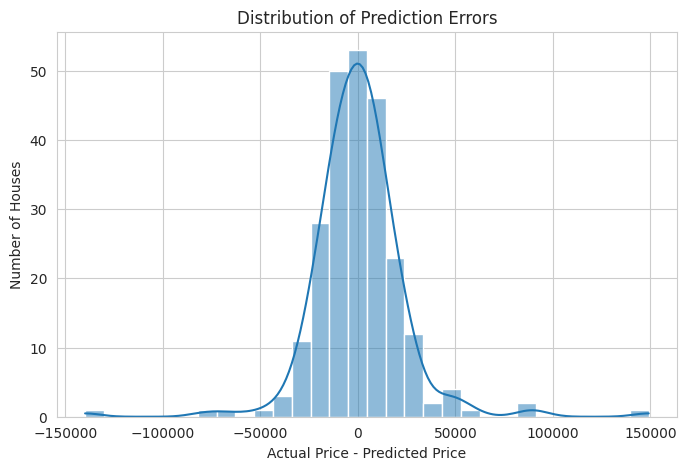

In [29]:
# Examine the prediction errors

residuals = y_val - val_predictions

plt.figure(figsize=(8, 5))

sns.histplot(residuals, bins=30, kde=True)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual Price - Predicted Price")
plt.ylabel("Number of Houses")

plt.show()

The first plot compares the actual house prices with the prices predicted by our model. Ideally, the points should be close to the diagonal line.

The second plot shows the prediction errors. This helps us see how much our predictions differ from the actual prices and whether the model tends to overestimate or underestimate them.

## 7. Final model and Kaggle submission

After evaluating our model, we train it again using the full training dataset instead of just the 80% training split.

This gives the model access to all the labelled observations before making predictions on the test dataset.

We then save the predictions in a CSV file so that they can be uploaded to Kaggle.

In [30]:
# Engineer features using all labelled training observations

X_eng = add_house_features(X)
X_test_eng = add_house_features(X_test)

# Identify numerical and categorical columns for the full dataset

numeric_features_final = X_eng.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features_final = X_eng.select_dtypes(
    exclude=np.number
).columns.tolist()

# Create a fresh preprocessing pipeline for the final model

preprocessor_final = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features_final),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", encoder)
    ]), categorical_features_final)
])

# Create the final SVR model

final_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", preprocessor_final),
        ("svr", SVR(
            kernel="rbf",
            C=5,
            gamma=0.008,
            epsilon=0.1
        ))
    ]),
    transformer=PowerTransformer(method="yeo-johnson")
)

print("Training final SVR model on all observations...")

final_model.fit(X_eng, y)

# Generate test predictions

test_predictions = final_model.predict(X_test_eng)
test_predictions = np.maximum(test_predictions, 0)

print("Predictions generated!")

Training final SVR model on all observations...
Predictions generated!


In [31]:
submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": test_predictions
})

output_path = (
    "/content/drive/MyDrive/DataBootcamp/Project2/"
    "Ames_Housing_SVR_Submission_Final.csv"
)

submission.to_csv(output_path, index=False)

print(submission.head())
print("Submission shape:", submission.shape)

     Id      SalePrice
0  1201   98265.527995
1  1202  195197.353147
2  1203  133315.081210
3  1204  201601.615651
4  1205  151543.828326
Submission shape: (260, 2)


## 8. Conclusion

For this project, we built a house price prediction model using Support Vector Regression.

We started by exploring the data and handling missing values. We then created additional features based on house size, quality, age, and other property characteristics.

After preprocessing the data, we trained an SVR model with an RBF kernel and used a Yeo-Johnson transformation on the sale prices. We evaluated the model using a separate validation set and RMSE.

Finally, we retrained the model using the full training dataset and generated predictions for our Kaggle submission.

Overall, this project gave us experience with data cleaning, feature engineering, model training, and evaluating regression models.